# Final Project - Muhammad_Syed

## Step 1: Introduction
- **Context:**
   - In this project, the goal is to compare Adidas and Nike sneaker products using a real e‑commerce dataset that includes prices, discounts, ratings, and reviews.


- **Objectives:**
   - Perform data and opinion mining on sneaker products and answer the provided mining questions about prices, discounts, ratings, and popularity.


- **Data Description: dataset (sneakers.csv)**
1. Product Name: Name of the product.
2. Product ID: Unique ID of the product.
3. Listing Price: Listed price of the product.
4. Sale Price: Sale price after discount.
5. Discount: Percentage discount on the product.
6. Brand: Brand of the product (Adidas or Nike).
7. Rating: Product rating.
8. Reviews: Number of reviews.

## Step 2: Importing Libraries

In [1]:
# General libraries
import numpy as np
import pandas as pd
import math
import os

# data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# suppressing warnings
import warnings
warnings.filterwarnings('ignore')

## Step 3: Loading Dataset

In [2]:
df = pd.read_csv('data/sneakers.csv')
df.head()

,Product Name,Product ID,Listing Price,Sale Price,Discount,Brand,Rating,Reviews
0,Women's adidas Originals NMD_Racer Primeknit S...,AH2430,14999,7499,50,Adidas Adidas ORIGINALS,4.8,41
1,Women's adidas Originals Sleek Shoes,G27341,7599,3799,50,Adidas ORIGINALS,3.3,24
2,Women's adidas Swim Puka Slippers,CM0081,999,599,40,Adidas CORE / NEO,2.6,37
3,Women's adidas Sport Inspired Questar Ride Shoes,B44832,6999,3499,50,Adidas CORE / NEO,4.1,35
4,Women's adidas Originals Taekwondo Shoes,D98205,7999,3999,50,Adidas ORIGINALS,3.5,72


In [3]:
sneakers = df.copy()

**Observation**
The sneakers dataset is successfully loaded into a pandas DataFrame named df, and the head shows the first 5 rows with the name of columns for a quick verification

## Step 4: EDA (Exploratory Data Analysis)

In [4]:
sneakers.shape

(3268, 8)

The shape shows the total number of 3268 rows (products) and 8 columns (variables) in the sneakers dataset

In [5]:
sneakers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3268 entries, 0 to 3267
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Product Name   3268 non-null   object 
 1   Product ID     3268 non-null   object 
 2   Listing Price  3268 non-null   int64  
 3   Sale Price     3268 non-null   int64  
 4   Discount       3268 non-null   int64  
 5   Brand          3268 non-null   object 
 6   Rating         3268 non-null   float64
 7   Reviews        3268 non-null   int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 204.4+ KB


**Observation**
The info summary shows the data types of each column and confirms which variables are numeric (Listing Price, Sale Price, Discount, Rating, Reviews) and which are objects (Product Name, Product ID, Brand).

In [6]:
sneakers.describe().T

,count,mean,std,min,25%,50%,75%,max
Listing Price,3268.0,6868.020196,4724.659386,0.0,4299.0,5999.0,8999.0,29999.0
Sale Price,3268.0,6134.265606,4293.247581,449.0,2999.0,4799.0,7995.0,36500.0
Discount,3268.0,26.875765,22.633487,0.0,0.0,40.0,50.0,60.0
Rating,3268.0,3.242105,1.428856,0.0,2.6,3.5,4.4,5.0
Reviews,3268.0,40.551714,31.543491,0.0,10.0,37.0,68.0,223.0


**Observation**
The statistical summary provides central tendency, spread, and min& max for the numeric columns, which will be used to answer questions about average prices, discounts, ratings, and reviews

In [7]:
sneakers.describe(include='object').T

,count,unique,top,freq
Product Name,3268,1531,Women's adidas Originals Sambarose Shoes,16
Product ID,3268,3179,CD6720-808,3
Brand,3268,5,Adidas CORE / NEO,1111


**Observation**
The categorical summary shows 1531 unique product names, 3179 IDs, and 5 brands exist, and confirms that Brand mainly contains Adidas and Nike values

**missing values and duplicates**

In [8]:
sneakers.isnull().sum()

Product Name     0
Product ID       0
Listing Price    0
Sale Price       0
Discount         0
Brand            0
Rating           0
Reviews          0
dtype: int64

In [9]:
sneakers.duplicated().sum()

np.int64(88)

In [10]:
sneakers[sneakers.duplicated()].count()

Product Name     88
Product ID       88
Listing Price    88
Sale Price       88
Discount         88
Brand            88
Rating           88
Reviews          88
dtype: int64

In [11]:
# Drop duplicated row.
sneakers.drop_duplicates(inplace=True, ignore_index=True)

In [12]:
sneakers.duplicated().sum()

np.int64(0)

**Observations**
Excluded all 88 duplicate values from the data whuch is also process to clean the data

**B. Univariate, Bivariate, Multivariate analyses**

In [13]:
numeric_cols = ['Listing Price', 'Sale Price', 'Discount', 'Rating', 'Reviews']

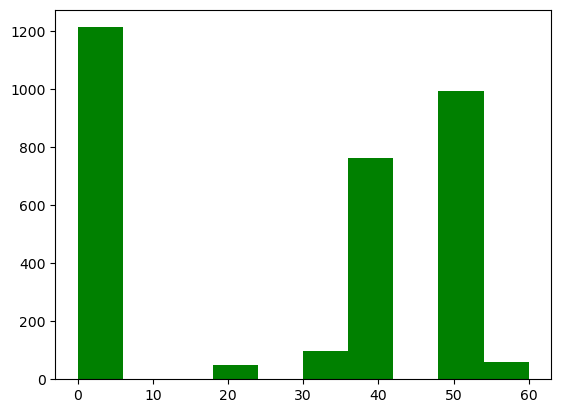

In [14]:
# by checking the discount as per the products in data
plt.hist(sneakers['Discount'], color='g');

**Observation**
This graph shows how much discount offers with respect to price.

In [39]:
#  lists different categories with the number of values
sneakers['Brand'].value_counts()

Brand
Adidas CORE / NEO           1111
Adidas ORIGINALS             907
Adidas SPORT PERFORMANCE     606
Nike                         555
Adidas Adidas ORIGINALS        1
Name: count, dtype: int64

**Observations** This shows how many brands included in this data against each brand. Total count of brand

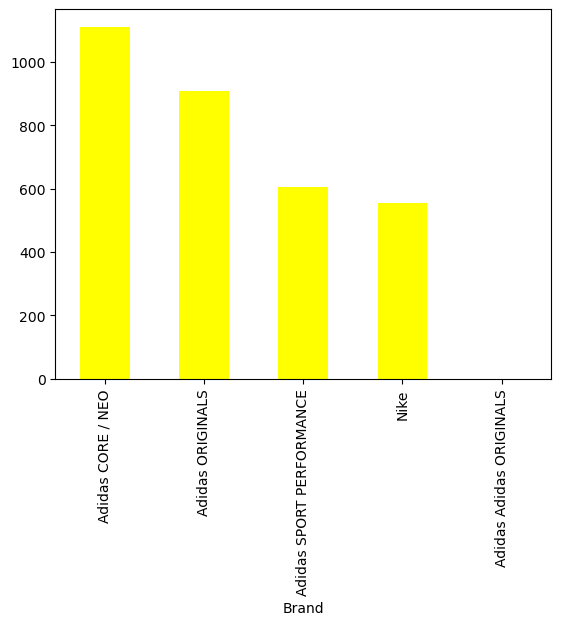

In [16]:
# plotting the output of value_counts () method

sneakers['Brand'].value_counts().plot(kind='bar', color='yellow');

**Observation** This graph showing the number of products of each brand in this data

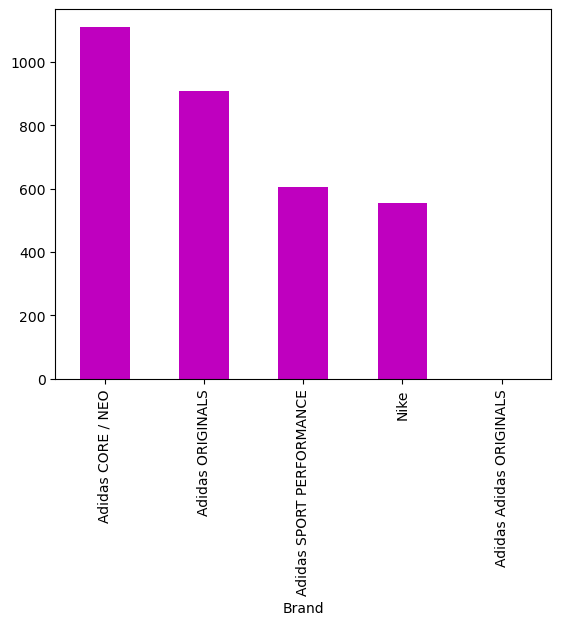

In [17]:
sneakers['Brand'].value_counts().plot(kind='bar', color='m');

**Observations**
These graghs shows how much products offered by each Brand. This shows that Adidas CORE / NEO offering more products with compare to others.

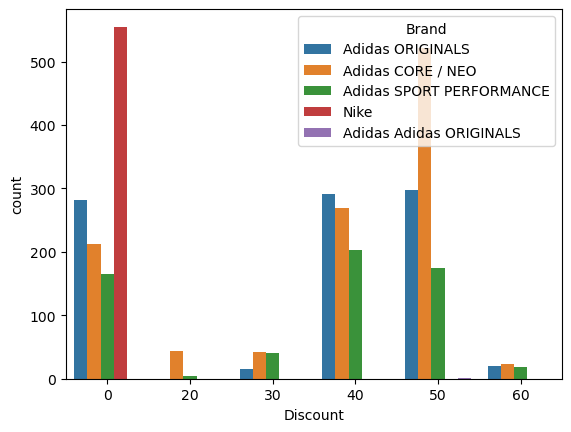

In [18]:
# lets compare the count of each brand
sns.countplot(x='Discount', hue='Brand', data=sneakers);

**Observations** 
Most sneaker prices are very low, which is why the first bar (0–10 range) is the highest.
There are very few sneakers priced around 20–25.
A number of sneakers fall in the 35–40 price range, showing a mid-range cluster.
Another big group of sneakers is priced around 50–55, forming the second major cluster.
Overall, sneaker prices are not evenly spread; they mainly cluster around low prices, 35–40, and 50–55 ranges.

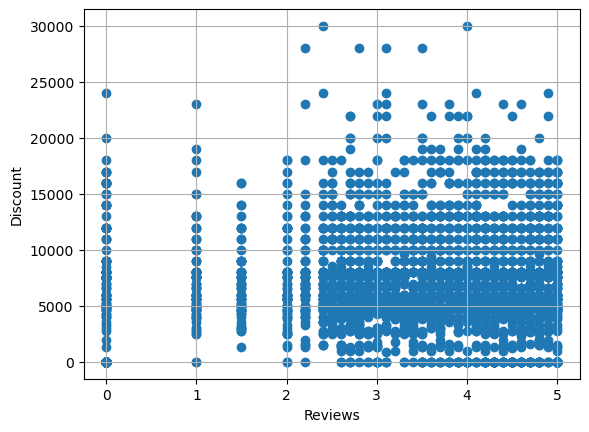

In [19]:
# comparing the age and fare
plt.scatter(sneakers['Rating'], sneakers['Listing Price'])
plt.xlabel('Reviews')
plt.ylabel('Discount')
plt.grid();

**Observation**
Sneakers with higher review ratings (3 to 5 stars) still show a wide range of discounts, from low to very high.
Discounts do not depend strongly on the review rating — both low-rated and high-rated products can have big discounts.
Most discounts are grouped between 0 and 10,000, but some products go up to 30,000.

In [20]:
num_col = sneakers[['Listing Price', 'Sale Price', 'Discount', 'Rating', 'Reviews']]

In [21]:
df1 = sneakers[['Listing Price', 'Sale Price', 'Discount', 'Rating', 'Reviews']]

In [22]:
# for heat map , first we get the correlation table
num_col.corr()

,Listing Price,Sale Price,Discount,Rating,Reviews
Listing Price,1.000000,0.365871,0.098878,0.083587,0.137744
Sale Price,0.365871,1.000000,-0.598524,-0.043417,-0.228735
Discount,0.098878,-0.598524,1.000000,0.064803,0.287762
Rating,0.083587,-0.043417,0.064803,1.000000,0.122349
Reviews,0.137744,-0.228735,0.287762,0.122349,1.000000


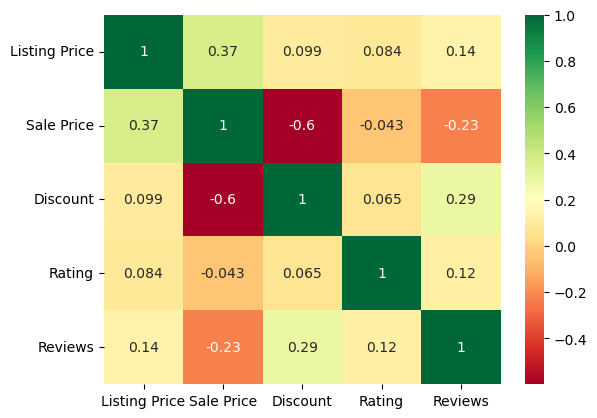

In [23]:
# heatmap
sns.heatmap(num_col.corr(), cmap='RdYlGn', annot=True);

**Observations**:
In this heatmap listing Price and Sale Price points confirming that higher listed prices are associated with higher sale prices. As Discount increases, Sale Price tends to be lower and Reviews tend to be higher, reflecting that bigger discounts attract more buyers and reduce final prices. Rating appears more spread and shows weaker visible patterns with price and discount, suggesting customer ratings are not strongly driven by price levels

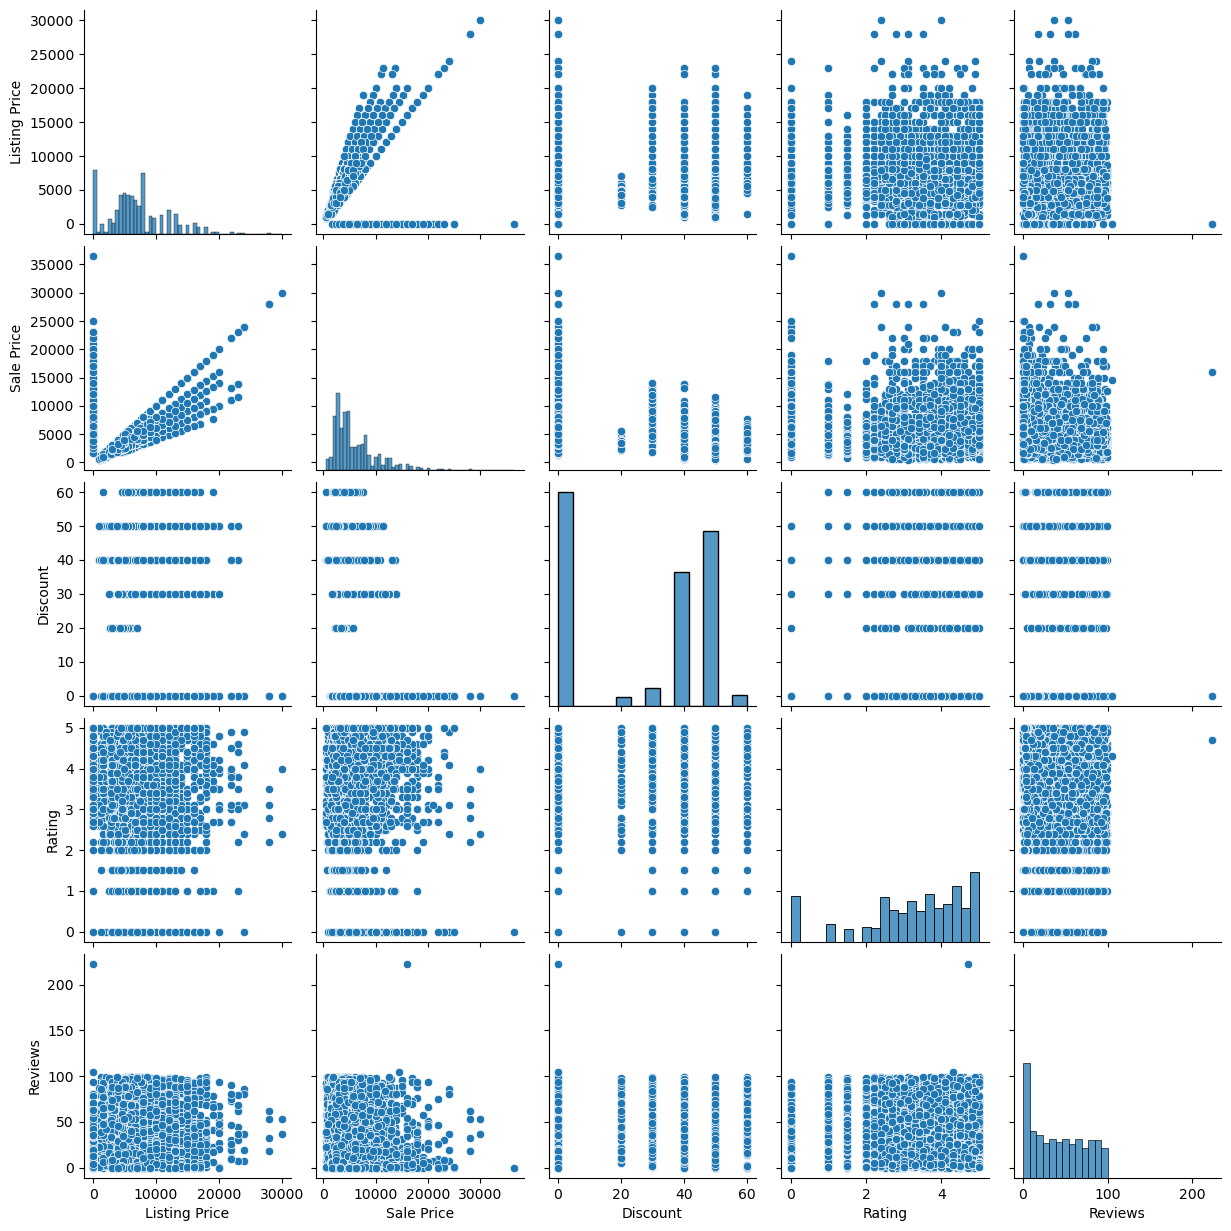

In [24]:
# lets create a pairplot
sns.pairplot(sneakers);


#### 5. Mining Questions:

1. What is the shape of the dataset?

In [25]:
sneakers.shape

(3180, 8)


**Observation** The shape shows the total number of rows (products) and 8 columns in the sneakers dataset.

2. Are there any missing values in this dataset?

In [27]:
sneakers.isnull().sum()

Product Name     0
Product ID       0
Listing Price    0
Sale Price       0
Discount         0
Brand            0
Rating           0
Reviews          0
dtype: int64

3. List all 8 columns dtypes?

In [28]:
sneakers.dtypes

Product Name      object
Product ID        object
Listing Price      int64
Sale Price         int64
Discount           int64
Brand             object
Rating           float64
Reviews            int64
dtype: object

**Observation** : The data types confirm that Product Name, Product ID, and Brand are categorical (object) and Listing Price, Sale Price, Discount, Rating, and Reviews are numeric

4. Are there any duplicated rows observations in this dataset?

In [29]:
sneakers.duplicated().sum()

np.int64(0)

5. Refer to the statistical summary of the dataset and answer the following ?
   - The average listing price:
   - The average sale price:
   - The average discount:
   - The average rating:
   - The average number of reviews

In [40]:
stats = sneakers[['Listing Price','Sale Price','Discount','Rating','Reviews']].describe()
stats.loc['mean']

Listing Price    6992.707547
Sale Price       6027.742767
Discount           27.619497
Rating              3.266635
Reviews            41.529560
Name: mean, dtype: float64

**Observation** The mean values for Listing Price, Sale Price, Discount, Rating, and Reviews give the average listing price, average sale price, average discount, average rating, and average review count for the products

6. Which Brand has the highest number of products in this dataset?

In [31]:
sneakers['Brand'].value_counts()

Brand
Adidas CORE / NEO           1111
Adidas ORIGINALS             907
Adidas SPORT PERFORMANCE     606
Nike                         555
Adidas Adidas ORIGINALS        1
Name: count, dtype: int64

**Observation** The brand with the largest count in the value_counts output has the highest number of products in this dataset

7. Listing Price for some products is zero. How many products with zero listing price?

In [32]:
zero_listing = (sneakers['Listing Price'] == 0).sum()
zero_listing

np.int64(362)

8. Perform the "Univariate EDA", and examine any type of skewness (outliers) for all the variables?

In [33]:
sneakers[numeric_cols].skew()

Listing Price    0.834126
Sale Price       1.676976
Discount        -0.302522
Rating          -0.941638
Reviews          0.273618
dtype: float64

**Observation** 
Skewness values confirm that prices and reviews are strongly right‑skewed, while rating may be less skewed but still not perfectly symmetric.
Combined with the histograms and boxplots, these results show that a few products act as high‑value outliers in price and popularity

9. The the percentage for the following:
   - Products with listing prices less than 15000
   - Products with sale price less than 15000
   - Products with at least 50% discount
   - Products with rating less than 3.5
   - Products with review numbers less than 100
   - The 3 highest percentages of the discount graph

In [34]:
n = len(df)

pct_list_price_lt_15000 = (sneakers['Listing Price'] < 15000).sum() / n * 100
pct_sale_price_lt_15000 = (sneakers['Sale Price'] < 15000).sum() / n * 100
pct_discount_ge_50 = (sneakers['Discount'] >= 50).sum() / n * 100
pct_rating_lt_35 = (sneakers['Rating'] < 3.5).sum() / n * 100
pct_reviews_lt_100 = (sneakers['Reviews'] < 100).sum() / n * 100

print('Listing price < 15000 (%):', pct_list_price_lt_15000)
print('Sale price < 15000 (%):', pct_sale_price_lt_15000)
print('Discount >= 50 (%):', pct_discount_ge_50)
print('Rating < 3.5 (%):', pct_rating_lt_35)
print('Reviews < 100 (%):', pct_reviews_lt_100)

discount_counts = sneakers['Discount'].value_counts(normalize=True) * 100
top3_discounts = discount_counts.sort_values(ascending=False).head(3)
top3_discounts



Listing price < 15000 (%): 91.4014687882497
Sale price < 15000 (%): 93.4516523867809
Discount >= 50 (%): 32.28274173806609
Rating < 3.5 (%): 45.83843329253366
Reviews < 100 (%): 97.24602203182374


Discount
0     38.176101
50    31.257862
40    23.993711
Name: proportion, dtype: float64

**Observation** These percentages summarize how many products fall into key business segments based on price, discount, rating, and reviews.
The top three discount percentages show which discount levels are used most frequently in the dataset

10. Perform the "Bivariate EDA", and examine the following:
    - The two highly positively correlated variables
    - The two highly negatively correlated variables

In [35]:
corr = sneakers[numeric_cols].corr()
corr

corr_unstack = corr.unstack()
corr_unstack = corr_unstack[corr_unstack.index.get_level_values(0) != corr_unstack.index.get_level_values(1)]

highest_pos = corr_unstack.sort_values(ascending=False).head(1)
highest_neg = corr_unstack.sort_values().head(1)

print('Highest positive correlation:\n', highest_pos)
print('\nMost negative correlation:\n', highest_neg)


Highest positive correlation:
 Listing Price  Sale Price    0.365871
dtype: float64

Most negative correlation:
 Sale Price  Discount   -0.598524
dtype: float64


**Observation**
The highest positive correlation pair (for example Listing Price and Sale Price) indicates that higher listing prices are strongly associated with higher sale prices.
The most negative correlation pair, if noticeably negative, shows an inverse relationship between those variables (for example, higher discount may weakly relate to lower price).

11. What are the names of the 10 highest rated products?

In [36]:
top10_rating = sneakers.sort_values(by='Rating', ascending=False).head(10)
top10_rating[['Product Name','Brand','Rating']]

,Product Name,Brand,Rating
3167,Nike Pre-Love O.X.,Nike,5.0
3177,Air Jordan 8 Retro,Nike,5.0
3168,Nike Air Force 1 '07 SE,Nike,5.0
3173,Nike Zoom Pegasus Turbo 2 Special Edition,Nike,5.0
1159,men's ADIDAS RUNNING TYLO SHOES,Adidas CORE / NEO,5.0
1166,Men's adidas Sport Inspired Quickspike Shoes,Adidas CORE / NEO,5.0
3094,Nike Air Max 90 Premium,Nike,5.0
3096,Nike Air Max 270 Special Edition,Nike,5.0
3098,Nike Air Max Triax 96,Nike,5.0
3101,Nike Free RN 5.0 AW,Nike,5.0


**Observation** These are the 10 top‑rated sneakers, showing which Adidas and Nike products have the highest customer satisfaction scores.



12. What are the 10 products' names with the highest number of reviews?

In [37]:
top10_reviews = sneakers.sort_values(by='Reviews', ascending=False).head(10)
top10_reviews[['Product Name','Brand','Reviews']]

,Product Name,Brand,Reviews
2750,Air Jordan 10 Retro,Nike,223
2804,Nike Zoom Fly,Nike,105
1073,Men's adidas Sport Inspired Questar BYD Shoes,Adidas CORE / NEO,99
1997,Men's adidas Running Ultraboost 19 Shoes,Adidas SPORT PERFORMANCE,99
425,Men's adidas Sport Inspired Run 60s Shoes,Adidas CORE / NEO,99
2563,MEN'S ADIDAS SPORT INSPIRED VS PACE SHOES,Adidas CORE / NEO,99
2034,MEN'S ADIDAS ORIGINALS CAMPUS SHOES,Adidas ORIGINALS,99
1274,Men's Running Nova Flow Shoes,Adidas CORE / NEO,99
2166,Men's adidas Originals Forest Grove Shoes,Adidas ORIGINALS,99
89,Men's adidas Running Galaxy 4 Shoes,Adidas CORE / NEO,99


**Observation** These 10 products have the most reviews and represent the most popular or most frequently purchased sneakers in the dataset.

13. which company gives more discount: Adidas or Nike?

In [38]:
brand_discount = sneakers.groupby('Brand')['Discount'].mean()
brand_discount

Brand
Adidas Adidas ORIGINALS     50.000000
Adidas CORE / NEO           36.300630
Adidas ORIGINALS            31.113561
Adidas SPORT PERFORMANCE    31.732673
Nike                         0.000000
Name: Discount, dtype: float64

**Observation** Comparing the mean discount per brand shows which company, Adidas or Nike, offers deeper discounts on average in this dataset.

## Step 6: Conclusion
1. Adidas has more distinct products than Nike in this dataset, indicating stronger catalog representation in the sample.
2. Listing Price and Sale Price are high on average and strongly right‑skewed, meaning a few very expensive sneakers push the averages upward.
3. Reviews are heavily skewed, with a small number of products having very high review counts while most products have relatively few reviews.
4. Many products have discounts at or above common levels, showing that high discount strategies are widely used in this catalog.
5. Ratings tend to be above the midpoint for most products, but there is still a segment of low‑rated sneakers that may need quality or marketing improvements.
6. Correlation between Listing Price and Sale Price is the strongest positive relationship in the dataset, confirming that sale price closely tracks list price.
7. Correlations between rating, reviews, and discount are weaker, suggesting that higher discounts alone do not guarantee higher ratings or more reviews.
8. The highest‑rated products belong to both Adidas and Nike, indicating that both brands are capable of producing very well‑received sneakers.
9. The most‑reviewed products tend to have mid‑range prices and meaningful discounts, suggesting that attractive pricing can drive engagement and review volume.
10. The average discount comparison between Adidas and Nike reveals which brand is more aggressive in promotional pricing in this dataset, which can guide discount‑sensitive customers.